# Análise exploratória das bases (EDA)

Este notebook olha **dentro** das duas bases que o bot usa. As regras de montagem (fontes, descartes,
duplicatas, carimbos) estão em [docs/dados.md](../docs/dados.md); aqui a pergunta é outra: *o que tem
nos dados e o que isso implica para as camadas 1 e 2?*

| Base | Arquivo | Usada por |
|---|---|---|
| Checagens | `data/processados/checagens/checagens.json` | camada 1 (busca) |
| Treino | `data/processados/treino/{treino,teste,teste_curtos}.csv` | camada 2 (classificador) |
| Entradas de teste do bot | `data/testes_benchmark.json`, `data/30_mensagens_teste.json` | comparação com o que o bot recebe |

**Antes de rodar:** as bases não ficam no git. Gere com `dvc repro checagens treino` (ou
`python -m checagens.bases.baixar && python -m checagens.bases.checagens && python -m checagens.bases.treino --corte 2018-09-15`)
na raiz do repositório. Rode este notebook a partir de `experiments/`, como os demais.

**Saídas:** figuras em `docs/img/eda/` (usadas em `docs/dados.md`) e tabelas em `results/eda_*.csv`.

Roteiro:
1. Base de checagens: tamanho e qualidade, veredito, tempo, agências, temas, texto das alegações
2. Base de treino: tamanho e classes, tempo, tamanho do texto, estilo, termos por classe, o que é "verdadeiro"
3. O que o bot recebe x o que está na base
4. Conclusões e implicações

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.metrics.pairwise import cosine_similarity

RAIZ = Path("..")
CHECAGENS = RAIZ / "data/processados/checagens/checagens.json"
TREINO = RAIZ / "data/processados/treino"
FIGS = RAIZ / "docs/img/eda"
RESULTS = Path("results")
FIGS.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(exist_ok=True)
assert CHECAGENS.exists(), "rode `dvc repro checagens treino` na raiz antes"

# Paleta categórica validada (ordem fixa, segura para daltonismo nos pares adjacentes)
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
CINZA = "#a8a7a1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#3d3c39", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold",
    "legend.frameon": False, "lines.linewidth": 2, "font.size": 10,
})


def salvar(fig, nome):
    fig.savefig(FIGS / f"{nome}.png")
    plt.show()


def fmt(n):
    return f"{n:,.0f}".replace(",", ".")

## 1. Base de checagens (camada 1)

### 1.1 Tamanho, campos e qualidade

In [2]:
chec = pd.DataFrame(json.loads(CHECAGENS.read_text()))
chec["data"] = pd.to_datetime(chec["data"])
chec["ano"] = chec["data"].dt.year
chec["fonte"] = chec["fonte_dataset"].str.replace("FactChecks.br/", "", regex=False)
chec["palavras"] = chec["alegacao"].str.split().str.len()

FONTES = ["Central de Fatos", "FactPolCheckBr", "FACTCK.BR", "FakeRecogna", "Google Fact Check Tools"]
COR_FONTE = dict(zip(FONTES, CORES))
VEREDITOS = ["falso", "enganoso", "verdadeiro", "outro"]
COR_VEREDITO = dict(zip(VEREDITOS, CORES))

print(f"{fmt(len(chec))} checagens, {chec.shape[1] - 4} campos originais")
print(f"período: {chec.data.min():%d/%m/%Y} a {chec.data.max():%d/%m/%Y}")
qualidade = pd.Series({
    "campos vazios": int((chec[["alegacao", "veredito_original", "agencia", "link"]] == "").sum().sum()),
    "nulos": int(chec.isna().sum().sum()),
    "ids repetidos": int(chec.id.duplicated().sum()),
    "links repetidos": int(chec.link.duplicated().sum()),
    "alegações repetidas (exatas)": int(chec.alegacao.str.lower().duplicated().sum()),
})
qualidade

12.245 checagens, 7 campos originais
período: 02/07/2013 a 08/10/2026


campos vazios                   0
nulos                           0
ids repetidos                   0
links repetidos                 0
alegações repetidas (exatas)    0
dtype: int64

A base sai limpa do pipeline: nenhum campo vazio, nenhuma duplicata de id, link ou alegação (o
`validar()` de `checagens.py` já garante isso). A EDA então se concentra na **composição**.

In [3]:
por_fonte = (chec.groupby("fonte")
             .agg(checagens=("id", "size"), inicio=("data", "min"), fim=("data", "max"),
                  agencias=("agencia", "nunique"), palavras_mediana=("palavras", "median"))
             .reindex(FONTES))
por_fonte["% da base"] = (100 * por_fonte.checagens / len(chec)).round(1)
por_fonte

,checagens,inicio,fim,agencias,palavras_mediana,% da base
fonte,,,,,,
Central de Fatos,7035,2013-07-02,2021-05-19,6,11.0,57.5
FactPolCheckBr,1804,2022-08-01,2022-12-01,11,12.0,14.7
FACTCK.BR,885,2016-06-15,2019-07-22,3,11.0,7.2
FakeRecogna,718,2018-11-13,2021-09-03,6,12.0,5.9
Google Fact Check Tools,1803,2025-10-08,2026-10-08,5,11.0,14.7


### 1.2 Veredito: quase tudo é `falso`

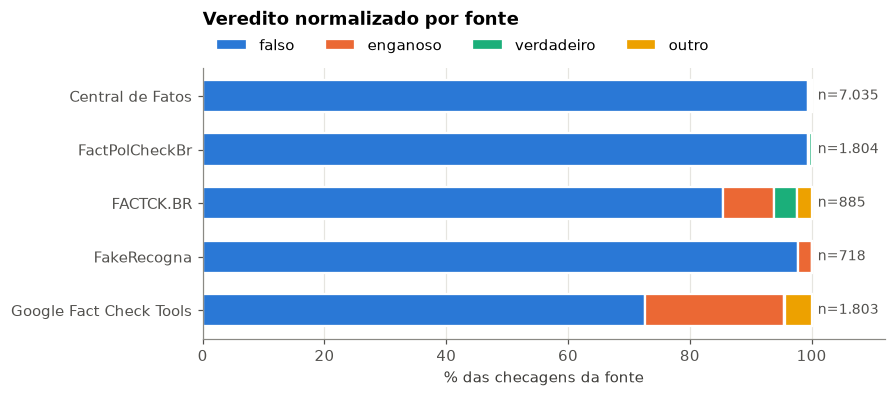

veredito_normalizado
falso         94.4
enganoso       4.3
outro          0.8
verdadeiro     0.5


In [4]:
ver = pd.crosstab(chec.fonte, chec.veredito_normalizado).reindex(index=FONTES, columns=VEREDITOS).fillna(0)
ver_pct = ver.div(ver.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 3.2))
esq = np.zeros(len(ver_pct))
for v in VEREDITOS:
    ax.barh(ver_pct.index, ver_pct[v], left=esq, color=COR_VEREDITO[v], label=v, height=0.6,
            edgecolor="white", linewidth=1.5)
    esq += ver_pct[v].values
for i, (f, n) in enumerate(ver.sum(axis=1).items()):
    ax.text(101, i, f"n={fmt(n)}", va="center", fontsize=9, color="#52514e")
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xlabel("% das checagens da fonte")
ax.grid(axis="y", visible=False)
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Veredito normalizado por fonte", pad=28)
salvar(fig, "checagens_veredito_por_fonte")

total = chec.veredito_normalizado.value_counts()
print((100 * total / total.sum()).round(1).to_string())

- **94% da base é `falso`.** Uma correspondência na busca quase sempre devolve "falso"; a base não
  serve para aprender o que é verdadeiro.
- A variedade de vereditos vem de duas fontes que trazem o rótulo da agência em campo próprio:
  **Google Fact Check Tools** (23% `enganoso`, "Fora de contexto", "Falta contexto") e **FACTCK.BR**.
  As fontes que dependem do carimbo no título (Central de Fatos, FakeRecogna) só capturam `falso`,
  porque é o carimbo que as agências mais usam no título.

In [5]:
(chec.groupby(["fonte", "veredito_original"]).size()
     .rename("checagens").reset_index()
     .sort_values(["fonte", "checagens"], ascending=[True, False])
     .groupby("fonte").head(6))

,fonte,veredito_original,checagens
1,Central de Fatos,#boato,5018
10,Central de Fatos,É falso,1135
5,Central de Fatos,É #FAKE,775
9,Central de Fatos,É falsa,38
2,Central de Fatos,Boato,21
8,Central de Fatos,É enganoso,16
22,FACTCK.BR,Falso,428
29,FACTCK.BR,falso,328
26,FACTCK.BR,Verdadeiro,32
27,FACTCK.BR,distorcido,29


### 1.3 Tempo: um buraco entre dez/2022 e out/2025

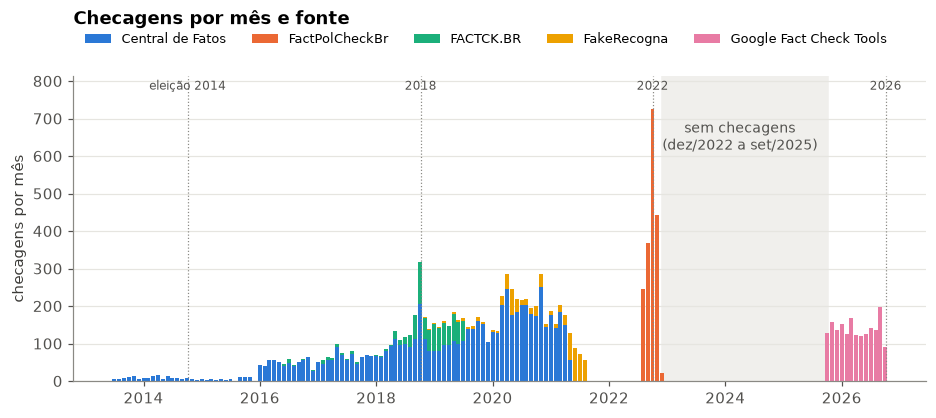

ano,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2025,2026
checagens,49,100,66,593,800,1604,1848,2514,1064,1804,421,1382


In [6]:
mensal = (chec.groupby([chec.data.dt.to_period("M"), "fonte"]).size()
          .unstack(fill_value=0).reindex(columns=FONTES, fill_value=0))
idx = pd.period_range("2013-07", chec.data.max().to_period("M"), freq="M")
mensal = mensal.reindex(idx, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 3.6))
x = mensal.index.to_timestamp()
base = np.zeros(len(mensal))
for f in FONTES:
    ax.bar(x, mensal[f], bottom=base, width=25, color=COR_FONTE[f], label=f, linewidth=0)
    base += mensal[f].values
ax.axvspan(pd.Timestamp("2022-12-02"), pd.Timestamp("2025-10-07"), color="#f0efec", zorder=0)
ax.text(pd.Timestamp("2024-04-01"), base.max() * 0.85, "sem checagens\n(dez/2022 a set/2025)",
        ha="center", fontsize=9, color="#52514e")
for d, rot in [("2014-10-05", "eleição 2014"), ("2018-10-07", "2018"), ("2022-10-02", "2022"), ("2026-10-04", "2026")]:
    ax.axvline(pd.Timestamp(d), color="#8a8984", lw=0.8, ls=":")
    ax.text(pd.Timestamp(d), base.max() * 1.07, rot, ha="center", fontsize=8, color="#52514e")
ax.set_ylim(0, base.max() * 1.12)
ax.set_ylabel("checagens por mês")
ax.legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.06), fontsize=8.5)
ax.set_title("Checagens por mês e fonte", pad=34)
ax.grid(axis="x", visible=False)
salvar(fig, "checagens_por_mes")

chec.groupby("ano").size().rename("checagens").to_frame().T

- Cada fonte cobre uma janela própria e quase não há sobreposição: Central de Fatos (2013 a 2021),
  FACTCK.BR (2016 a 2019), FakeRecogna (2018 a 2021), FactPolCheckBr (só ago a dez/2022) e Google
  Fact Check Tools (out/2025 em diante).
- **Não há nada entre dez/2022 e set/2025.** Boatos desse período (p.ex. 8 de janeiro, enchentes no
  RS em 2024) só serão encontrados se o Google Fact Check os tiver republicado.
- O pico de out/2022 (726 checagens) é a campanha presidencial; o de 2020 é a pandemia.
- A entrada do Google Fact Check deixa a base com ~140 checagens/mês de 2025-26: é ela que dá
  cobertura à campanha de 2026.

### 1.4 Agências: concentração no Boatos.org

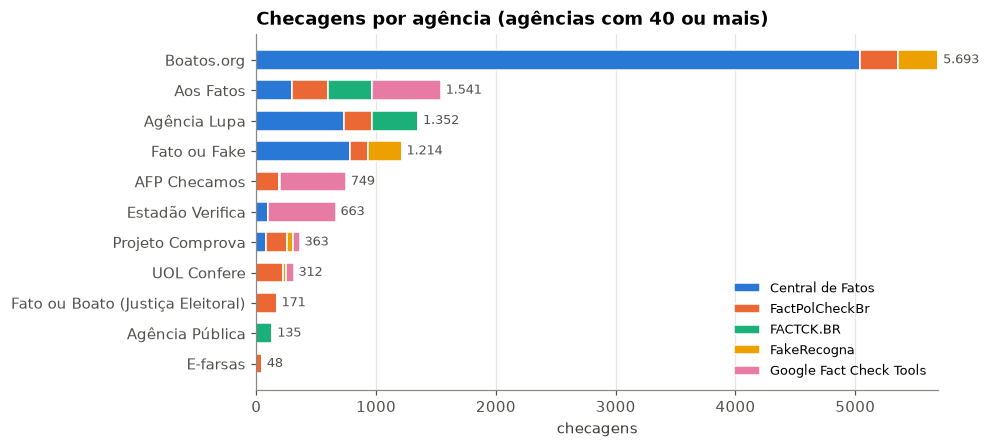

Boatos.org: 46% da base; agências com < 40 checagens: ['Folha de S. Paulo', 'CNJ', 'UOL']


In [7]:
ag = pd.crosstab(chec.agencia, chec.fonte).reindex(columns=FONTES, fill_value=0)
ag = ag.loc[ag.sum(axis=1).sort_values(ascending=False).index]
ag_top = ag[ag.sum(axis=1) >= 40]

fig, ax = plt.subplots(figsize=(8, 4.2))
esq = np.zeros(len(ag_top))
for f in FONTES:
    ax.barh(ag_top.index, ag_top[f], left=esq, color=COR_FONTE[f], label=f, height=0.65,
            edgecolor="white", linewidth=1)
    esq += ag_top[f].values
for i, n in enumerate(ag_top.sum(axis=1)):
    ax.text(n + 40, i, fmt(n), va="center", fontsize=8.5, color="#52514e")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("checagens")
ax.legend(fontsize=8.5, loc="lower right")
ax.set_title("Checagens por agência (agências com 40 ou mais)")
salvar(fig, "checagens_por_agencia")

top1 = ag.sum(axis=1).iloc[0] / len(chec)
print(f"{ag.index[0]}: {100 * top1:.0f}% da base; agências com < 40 checagens: {list(ag.index[ag.sum(axis=1) < 40])}")

**Boatos.org responde por 46% da base**, quase tudo antes de 2023. Como a busca devolve a checagem
mais parecida, a maior parte dos acertos vai mostrar o Boatos.org, e o estilo das alegações dele
(títulos curtos, "#boato") domina o índice. Aos Fatos, Estadão Verifica e AFP só ganham peso graças ao
Google Fact Check (2025-26).

### 1.5 Temas: o que foi checado em cada época

Contagem por expressões regulares simples, só para ver a ordem de grandeza. Uma alegação pode cair em
mais de um tema.

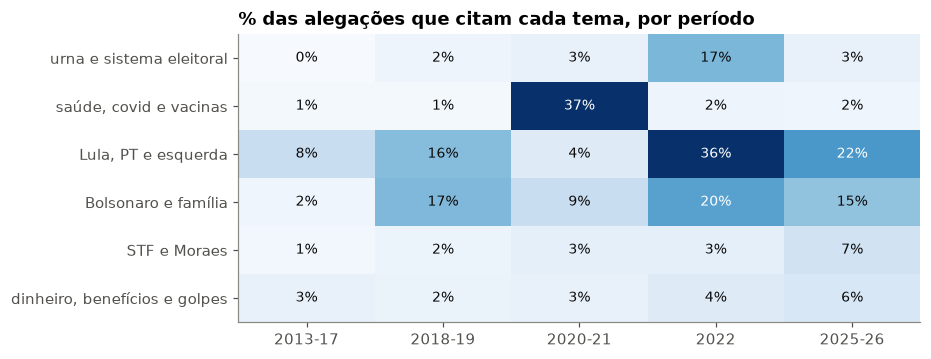

,urna e sistema eleitoral,"saúde, covid e vacinas","Lula, PT e esquerda",Bolsonaro e família,STF e Moraes,"dinheiro, benefícios e golpes"
periodo,,,,,,
2013-17,0.2,0.8,8.5,1.7,0.9,2.7
2018-19,1.8,0.7,15.8,16.6,2.0,2.3
2020-21,2.8,36.7,4.5,8.6,3.2,2.7
2022,16.9,1.8,36.5,20.4,3.4,4.5
2025-26,2.8,1.6,22.0,14.9,7.1,5.7


In [8]:
TEMAS = {
    "urna e sistema eleitoral": r"\burnas?\b|\btse\b|voto impresso|apura[çc][ãa]o|biometria|t[íi]tulo de eleitor|fraude eleitoral",
    "saúde, covid e vacinas": r"covid|coronav[íi]rus|vacina|cloroquina|ivermectina|pandemia|lockdown",
    "Lula, PT e esquerda": r"\blula\b|\bpt\b|dilma|haddad|petista",
    "Bolsonaro e família": r"bolsonaro|michelle",
    "STF e Moraes": r"\bstf\b|moraes|supremo",
    "dinheiro, benefícios e golpes": r"\bpix\b|bolsa fam[íi]lia|aux[íi]lio|\binss\b|aposentad|sal[áa]rio|imposto|golpe do",
}
for t, p in TEMAS.items():
    chec[t] = chec.alegacao.str.contains(p, case=False, regex=True)

chec["periodo"] = pd.cut(chec.ano, [2012, 2017, 2019, 2021, 2022, 2026],
                         labels=["2013-17", "2018-19", "2020-21", "2022", "2025-26"])
temas = (100 * chec.groupby("periodo", observed=True)[list(TEMAS)].mean()).round(1)
temas.to_csv(RESULTS / "eda_temas_por_periodo.csv")

fig, ax = plt.subplots(figsize=(8, 3.4))
im = ax.imshow(temas.T.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(temas.index)), temas.index)
ax.set_yticks(range(len(TEMAS)), list(TEMAS))
for i in range(temas.shape[1]):
    for j in range(temas.shape[0]):
        v = temas.iloc[j, i]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                color="white" if v > temas.values.max() * 0.55 else "#0b0b0b")
ax.grid(False)
ax.set_title("% das alegações que citam cada tema, por período")
salvar(fig, "checagens_temas")
temas

- **Urna e sistema eleitoral** é marca de 2022 (17%, 1 em cada 6 checagens) e quase não aparece
  antes. São os boatos que mais devem voltar em 2026, e a base tem cerca de 300 deles.
- **Lula/PT** é o tema mais checado em 2022 (36%) e continua alto em 2025-26 (22%); Bolsonaro vem logo
  atrás. A base é muito centrada nos dois polos da eleição presidencial.
- **Covid** é 37% de 2020-21 e some depois: volume grande da base com pouca utilidade para a eleição.
- Em 2025-26 crescem **STF/Moraes** (7%) e **dinheiro, benefícios e golpes** (6%: Pix, INSS, Bolsa
  Família).

### 1.6 Texto das alegações

Duas propriedades do texto importam para a busca: o **tamanho** (a alegação é comparada com a
mensagem inteira do usuário) e a **negação** (a camada 1 nunca responde "já checado" quando só um dos
lados tem negação).

In [9]:
NEG = r"\b(?:não|nao|nunca|jamais|nem)\b"
chec["negacao"] = chec.alegacao.str.contains(NEG, case=False, regex=True)

texto = (chec.groupby("fonte")
         .agg(palavras_p10=("palavras", lambda s: s.quantile(.1)), palavras_mediana=("palavras", "median"),
              palavras_p90=("palavras", lambda s: s.quantile(.9)), com_negacao_pct=("negacao", "mean"))
         .reindex(FONTES))
texto["com_negacao_pct"] = (100 * texto.com_negacao_pct).round(1)
texto

,palavras_p10,palavras_mediana,palavras_p90,com_negacao_pct
fonte,,,,
Central de Fatos,8.0,11.0,15.0,5.7
FactPolCheckBr,9.0,12.0,17.0,34.5
FACTCK.BR,8.0,11.0,15.0,43.6
FakeRecogna,9.0,12.0,16.0,7.0
Google Fact Check Tools,7.0,11.0,18.8,8.4


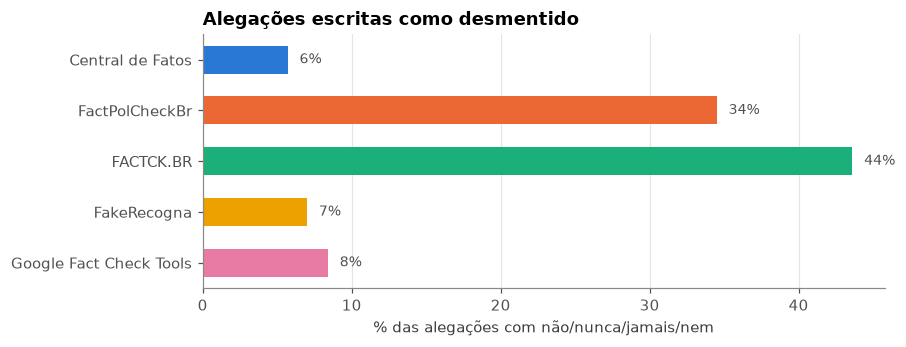

FACTCK.BR -> ["Haddad não disse que Bolsonaro faltou a debate porque 'fede'; justificativa é de aliado do deputado", 'Avião em queda mostrado em vídeo não tem relação com acidente na Etiópia', 'Damares não cancelou indenizações de anistiados políticos']
FactPolCheckBr -> ['Ao contrário do que afirma vídeo, Lula não disse que vai implantar ditadura no Brasil em entrevista a canal chinês', 'Maiara e Maraisa não gritaram ‘fora Bolsonaro’ nem deixaram palco sob vaias', 'Este vídeo exibe festa de torcida de futebol na Croácia em 2020, não vitória de Lula em 2022']


In [10]:
fig, ax = plt.subplots(figsize=(8, 3))
neg = texto.com_negacao_pct
ax.barh(neg.index, neg, color=[COR_FONTE[f] for f in neg.index], height=0.55)
for i, v in enumerate(neg):
    ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=9, color="#52514e")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("% das alegações com não/nunca/jamais/nem")
ax.set_title("Alegações escritas como desmentido")
salvar(fig, "checagens_negacao")

for f in ["FACTCK.BR", "FactPolCheckBr"]:
    print(f, "->", chec[(chec.fonte == f) & chec.negacao].alegacao.sample(3, random_state=1).tolist())

- As alegações são **curtas**: mediana de 11 a 12 palavras em todas as fontes. O Google Fact Check
  tem a cauda mais longa (até 77 palavras).
- **43% das alegações do FACTCK.BR e 35% das do FactPolCheckBr têm negação**, contra 6% a 8% nas
  outras. Nessas fontes o título costuma ser o desmentido ("Lula não disse que…"), não o boato. Para
  a busca, isso quer dizer que a mensagem do usuário (o boato, sem negação) e a alegação (com
  negação) diferem justamente no ponto que a regra de negação da camada 1 vigia. É uma fonte
  previsível de "notícia parecida" em vez de "já checado".

## 2. Base de treino (camada 2)

### 2.1 Tamanho e classes

In [11]:
arquivos = {n: pd.read_csv(TREINO / f"{n}.csv", dtype={"data": "string"}) for n in ["treino", "teste", "teste_curtos"]}
tr = pd.concat([d.assign(arquivo=n) for n, d in arquivos.items()], ignore_index=True)
tr["data"] = pd.to_datetime(tr["data"], errors="coerce")
tr["palavras"] = tr.texto.str.split().str.len()
ROTULOS = ["falso", "verdadeiro"]
COR_ROTULO = dict(zip(ROTULOS, CORES))
ORDEM = [("treino", "Fake.br-Corpus"), ("treino", "FakeWhatsApp.Br"), ("teste", "FakeWhatsApp.Br"), ("teste_curtos", "FakeTweet.Br")]

classes = pd.crosstab([tr.arquivo, tr.fonte], tr.rotulo).reindex(ORDEM)
classes["linhas"] = classes.sum(axis=1)
classes["% falso"] = (100 * classes.falso / classes.linhas).round(1)
classes

rotulo                        falso  verdadeiro  linhas  % falso
arquivo      fonte                                              
treino       Fake.br-Corpus    3600        3599    7199     50.0
             FakeWhatsApp.Br   1162        1573    2735     42.5
teste        FakeWhatsApp.Br   1628        1667    3295     49.4
teste_curtos FakeTweet.Br       199          98     297     67.0

As classes estão equilibradas em treino e teste (48% e 49% de falso); só o `teste_curtos` (FakeTweet)
pende para falso (67%). O treino é **72% Fake.br** (notícias de site) e só 28% mensagens de
WhatsApp, enquanto o teste é 100% WhatsApp.

### 2.2 Tempo: o Fake.br separa as classes por ano

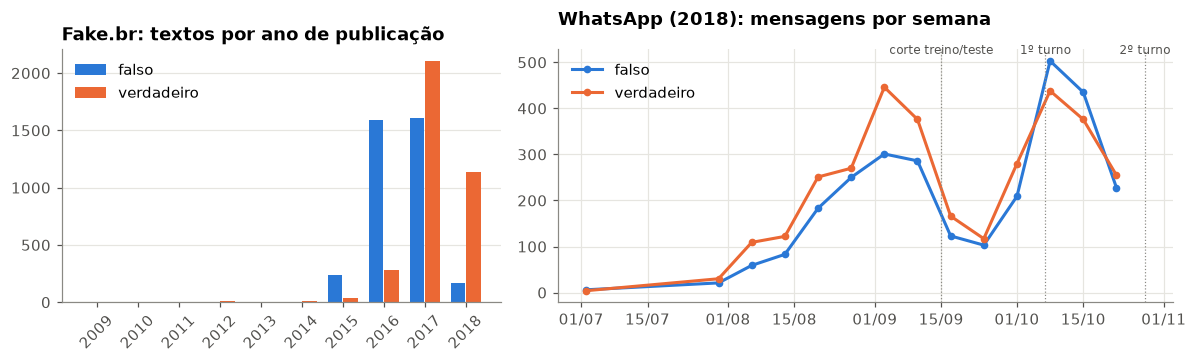

data,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
rotulo,,,,,,,,,,
falso,0,0,0,1,0,0,235,1586,1606,169
verdadeiro,3,6,5,9,5,10,40,278,2101,1138


In [12]:
fb = tr[tr.fonte == "Fake.br-Corpus"]
fb_ano = pd.crosstab(fb.data.dt.year.astype("Int64"), fb.rotulo).reindex(columns=ROTULOS, fill_value=0)

wa = tr[tr.fonte == "FakeWhatsApp.Br"]
wa_dia = pd.crosstab(wa.data.dt.to_period("W").dt.start_time, wa.rotulo).reindex(columns=ROTULOS, fill_value=0)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.4]})
x = np.arange(len(fb_ano))
for k, r in enumerate(ROTULOS):
    a1.bar(x + (k - .5) * .38, fb_ano[r], width=.36, color=COR_ROTULO[r], label=r)
a1.set_xticks(x, fb_ano.index.astype(str), rotation=45)
a1.grid(axis="x", visible=False)
a1.set_title("Fake.br: textos por ano de publicação")
a1.legend()

for r in ROTULOS:
    a2.plot(wa_dia.index, wa_dia[r], color=COR_ROTULO[r], label=r, marker="o", ms=4)
for d, rot in [("2018-09-15", "corte treino/teste"), ("2018-10-07", "1º turno"), ("2018-10-28", "2º turno")]:
    a2.axvline(pd.Timestamp(d), color="#8a8984", lw=0.8, ls=":")
    a2.text(pd.Timestamp(d), wa_dia.values.max() * 1.03, rot, ha="center", fontsize=8, color="#52514e")
a2.xaxis.set_major_formatter(__import__("matplotlib.dates").dates.DateFormatter("%d/%m"))
a2.set_title("WhatsApp (2018): mensagens por semana", pad=16)
a2.legend(loc="upper left")
fig.tight_layout()
salvar(fig, "treino_tempo")

fb_ano.T

In [13]:
f17 = fb.data.dt.year
print(f"Fake.br falso publicado até 2016: {100 * (f17[fb.rotulo == 'falso'] <= 2016).mean():.0f}%")
print(f"Fake.br verdadeiro publicado em 2017-18: {100 * (f17[fb.rotulo == 'verdadeiro'] >= 2017).mean():.0f}%")
print(f"AUC do ano sozinho como preditor de falso no Fake.br: "
      f"{roc_auc_score(fb.rotulo[f17.notna()] == 'falso', -f17.dropna()):.2f}")

Fake.br falso publicado até 2016: 51%
Fake.br verdadeiro publicado em 2017-18: 90%
AUC do ano sozinho como preditor de falso no Fake.br: 0.76


- **No Fake.br, o ano separa bem as classes.** As falsas são de 2015 a 2017 (metade até 2016) e 90%
  das verdadeiras são de 2017-18; o ano sozinho tem AUC de 0,76. Na prática, o modelo pode aprender
  **assuntos da época** (impeachment e Dilma em 2016; Temer e eleição de 2018) como se fossem sinal
  de falsidade. É mais uma explicação, além do estilo dos sites, para a camada 2 não ter
  passado no critério.
- No WhatsApp, o volume cresce até a eleição e a proporção de falso **sobe depois do 1º turno**
  (semanas de 8 a 21/10 têm mais falso que verdadeiro), então o teste tem uma distribuição um pouco
  diferente do treino.

### 2.3 Tamanho do texto: um atalho no WhatsApp

Se o tamanho do texto sozinho separa as classes, um classificador pode aprender "texto longo = falso"
em vez de sinais de desinformação. O AUC do número de palavras mede isso (0,5 = não separa).

In [14]:
def auc_tamanho(d):
    return roc_auc_score(d.rotulo == "falso", d.palavras)

tam = (tr.groupby(["arquivo", "fonte", "rotulo"]).palavras.median().unstack().reindex(ORDEM)
         .rename(columns=lambda c: f"mediana_{c}"))
tam["AUC_tamanho"] = [auc_tamanho(tr[(tr.arquivo == a) & (tr.fonte == f)]) for a, f in ORDEM]
tam.round(2).to_csv(RESULTS / "eda_tamanho_texto.csv")
tam.round(2)

rotulo                        mediana_falso  mediana_verdadeiro  AUC_tamanho
arquivo      fonte                                                          
treino       Fake.br-Corpus           156.0               158.0         0.49
             FakeWhatsApp.Br           57.0                28.0         0.67
teste        FakeWhatsApp.Br           44.0                30.0         0.63
teste_curtos FakeTweet.Br              29.0                27.5         0.52

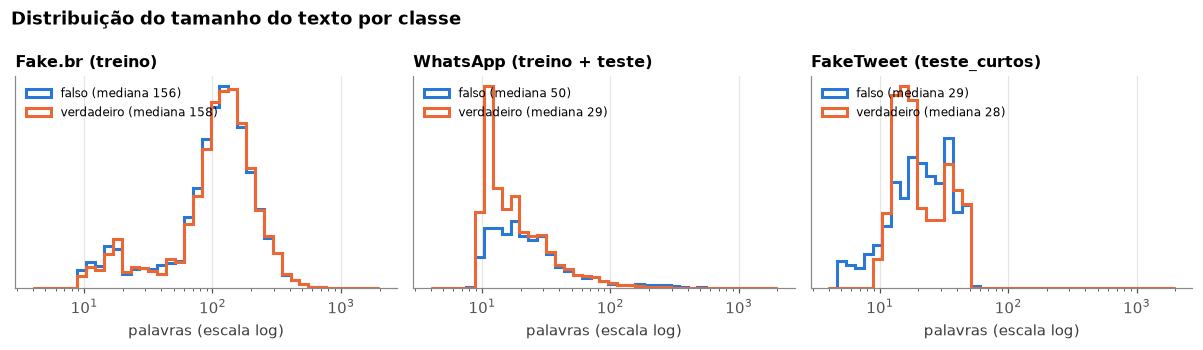

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2), sharey=False)
bins = np.logspace(0.6, 3.3, 40)
for ax, (rot, d) in zip(axs, [("Fake.br (treino)", tr[tr.fonte == "Fake.br-Corpus"]),
                              ("WhatsApp (treino + teste)", tr[tr.fonte == "FakeWhatsApp.Br"]),
                              ("FakeTweet (teste_curtos)", tr[tr.fonte == "FakeTweet.Br"])]):
    for r in ROTULOS:
        ax.hist(d[d.rotulo == r].palavras, bins=bins, histtype="step", lw=2, color=COR_ROTULO[r],
                label=f"{r} (mediana {d[d.rotulo == r].palavras.median():.0f})", density=True)
    ax.set_xscale("log")
    ax.set_title(rot, fontsize=10.5)
    ax.set_xlabel("palavras (escala log)")
    ax.set_yticks([])
    ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Distribuição do tamanho do texto por classe", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "treino_tamanho_texto")

- No **Fake.br** o tamanho não diz nada (AUC 0,49): os pares foram cortados para o mesmo tamanho
  (`size_normalized_texts`).
- No **WhatsApp**, as falsas têm **o dobro do tamanho** das verdadeiras (mediana 57 x 28 palavras no
  treino; 44 x 30 no teste) e o tamanho sozinho tem AUC de 0,67 no treino e 0,63 no teste. Correntes
  longas são, em geral, desinformação; mensagens curtas de conversa, não.
- Isso não é necessariamente vazamento (texto longo e alarmista é um sinal real de corrente), mas
  explica parte da métrica e não se transfere para tweets (AUC 0,52).

### 2.4 Estilo: o que muda entre fontes e classes

Marcas de formatação que um classificador TF-IDF pode capturar.

In [16]:
EMOJI = r"[\U0001F300-\U0001FAFF\u2600-\u27BF]"
tr["tem_link"] = tr.texto.str.contains(r"https?://")
tr["2+ exclamações"] = tr.texto.str.count("!") >= 2
tr["30%+ maiúsculas"] = tr.texto.map(lambda t: sum(c.isupper() for c in t) / max(1, sum(c.isalpha() for c in t))) > 0.3
tr["tem_emoji"] = tr.texto.str.contains(EMOJI)
tr["negrito *assim*"] = tr.texto.str.contains(r"\*\w")
tr["pede para repassar"] = tr.texto.str.contains(r"compartilh|repass|divulgu|espalh", case=False)
tr["urgente/atenção"] = tr.texto.str.contains(r"urgente|aten[çc][ãa]o|alerta", case=False)
ESTILO = ["tem_link", "2+ exclamações", "30%+ maiúsculas", "tem_emoji", "negrito *assim*", "pede para repassar", "urgente/atenção"]

estilo = (100 * tr.groupby(["fonte", "rotulo"])[ESTILO].mean()).round(1)
estilo.to_csv(RESULTS / "eda_estilo.csv")
estilo

tem_link  2+ exclamações  30%+ maiúsculas  \
fonte           rotulo                                                  
Fake.br-Corpus  falso            0.0            14.3              0.1   
                verdadeiro       0.5             0.6              0.0   
FakeTweet.Br    falso           32.7            12.6              9.0   
                verdadeiro      42.9             2.0              3.1   
FakeWhatsApp.Br falso           22.7            32.9             10.3   
                verdadeiro      27.2            19.3              8.5   

                            tem_emoji  negrito *assim*  pede para repassar  \
fonte           rotulo                                                       
Fake.br-Corpus  falso             0.0              0.1                 6.0   
                verdadeiro        0.0              0.3                 4.3   
FakeTweet.Br    falso             0.0              1.0                 3.0   
                verdadeiro        0.0              0.0                 7.1   
FakeWhatsApp.Br falso            32.6             23.5                25.0   
                verdadeiro       34.4             22.8                12.4   

                            urgente/atenção  
fonte           rotulo                       
Fake.br-Corpus  falso                   9.0  
                verdadeiro              4.9  
FakeTweet.Br    falso                   5.0  
                verdadeiro              1.0  
FakeWhatsApp.Br falso                  11.9  
                verdadeiro              5.5

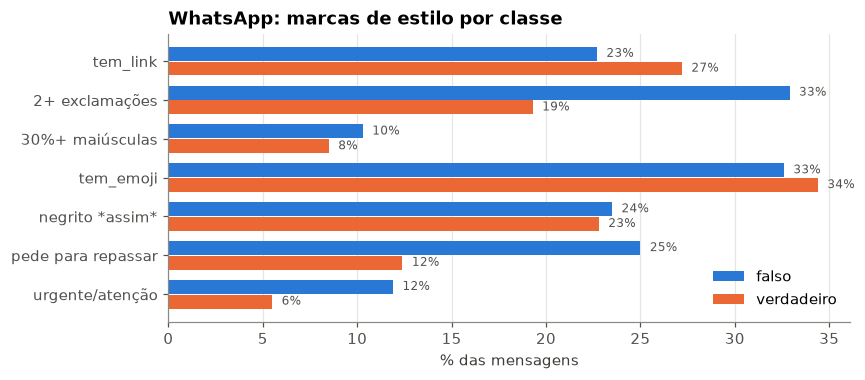

In [17]:
wa_est = estilo.loc["FakeWhatsApp.Br"].T
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(wa_est))
for k, r in enumerate(ROTULOS):
    ax.barh(y + (k - .5) * .38, wa_est[r], height=.36, color=COR_ROTULO[r], label=r)
    for yi, v in zip(y, wa_est[r]):
        ax.text(v + .5, yi + (k - .5) * .38, f"{v:.0f}%", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, wa_est.index)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("% das mensagens")
ax.legend(loc="lower right")
ax.set_title("WhatsApp: marcas de estilo por classe")
salvar(fig, "treino_estilo_whatsapp")

- **WhatsApp:** "pede para repassar", "2+ exclamações" e "urgente/atenção" são bem mais comuns nas
  falsas. São sinais de estilo que o bot pode mostrar (RF-08). Link, emoji e negrito aparecem nas duas
  classes na mesma proporção: são o jeito de escrever no canal, não da desinformação.
- **Fake.br vs WhatsApp:** emoji, negrito e link praticamente não existem no Fake.br. O modelo treinado
  com 72% de Fake.br vê pouco do formato que vai receber.
- **Fake.br:** 14% das falsas têm 2+ exclamações, contra 0,6% das verdadeiras: estilo dos sites de
  origem.

### 2.5 Termos que mais distinguem as classes

Log-odds com prior de Dirichlet (Monroe et al., 2008): mostra as palavras cuja frequência mais difere
entre falso e verdadeiro, corrigindo palavras raras. Feito separadamente para Fake.br e WhatsApp do
treino.

In [18]:
def log_odds(textos, rotulos, n=12):
    cv = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b[^\W\d_]{3,}\b", min_df=5)
    X = cv.fit_transform(textos)
    voc = np.array(cv.get_feature_names_out())
    a = np.asarray(X[(rotulos == "falso").values].sum(0)).ravel()
    b = np.asarray(X[(rotulos == "verdadeiro").values].sum(0)).ravel()
    prior = np.asarray(X.sum(0)).ravel() * 0.01 + 0.01
    a0, b0, p0 = a.sum(), b.sum(), prior.sum()
    delta = (np.log((a + prior) / (a0 + p0 - a - prior)) - np.log((b + prior) / (b0 + p0 - b - prior)))
    z = delta / np.sqrt(1 / (a + prior) + 1 / (b + prior))
    ordem = np.argsort(z)
    return pd.DataFrame({"mais falso": voc[ordem[::-1][:n]], "z falso": z[ordem[::-1][:n]].round(1),
                         "mais verdadeiro": voc[ordem[:n]], "z verd.": (-z[ordem[:n]]).round(1)})

base_tr = tr[tr.arquivo == "treino"]
for f in ["Fake.br-Corpus", "FakeWhatsApp.Br"]:
    d = base_tr[base_tr.fonte == f]
    print(f)
    display(log_odds(d.texto, d.rotulo))

Fake.br-Corpus


,mais falso,z falso,mais verdadeiro,z verd.
0,dilma,23.6,feira,33.5
1,não,18.7,nesta,27.7
2,disse,17.8,tribunal,19.9
3,está,17.6,quarta,18.4
4,vídeo,15.2,terça,17.2
5,lula,15.2,segunda,16.8
6,globo,13.7,federal,16.6
7,jornalista,13.1,quinta,16.4
8,pra,12.9,segundo,16.0
9,através,12.7,ano,15.6


FakeWhatsApp.Br


,mais falso,z falso,mais verdadeiro,z verd.
0,que,11.4,whatsapp,19.8
1,sem,9.4,chat,16.8
2,esquerda,8.6,https,16.3
3,voto,8.0,bolsonaro,15.7
4,como,7.4,senador,13.3
5,não,7.3,palmas,11.7
6,país,7.3,grupo,11.1
7,lula,6.8,dep,10.7
8,escolas,6.5,psl,10.0
9,radical,6.4,link,10.0


Leitura (os números exatos estão na tabela acima):
- **Fake.br:** os termos "verdadeiros" são marcas de texto de agência de notícias: dias da semana
  ("nesta quarta-feira"), "tribunal", "federal", "segundo". Os "falsos" são linguagem de blog e
  opinião ("pra", "povo", "através", "jornalista", "vídeo") e os personagens de 2016 ("Dilma",
  "Lula"). Confirma 2.2: o modelo pode aprender **o veículo e a época**, não a desinformação.
- **WhatsApp:** os termos "falsos" são de pauta ideológica ("esquerda", "radical", "escolas",
  "crianças", "voto"). Os "verdadeiros" são **convites para grupos** ("whatsapp", "chat", "link",
  "https") e **propaganda de candidatos locais** ("senador", "dep", "estadual", "PSL", "Palmas",
  "Tocantins"). O rótulo verdadeiro carrega a geografia dos grupos coletados, que não se repete em
  2026.

### 2.6 O que é "verdadeiro" em cada fonte

O rótulo não tem o mesmo significado nas três bases. Amostras aleatórias de textos curtos para ver na
prática:

In [19]:
pd.set_option("display.max_colwidth", 160)
amostras = []
for f in ["Fake.br-Corpus", "FakeWhatsApp.Br", "FakeTweet.Br"]:
    d = tr[(tr.fonte == f) & (tr.rotulo == "verdadeiro")]
    amostras.append(d.sample(4, random_state=7)[["fonte", "texto"]].assign(texto=lambda x: x.texto.str[:160]))
pd.concat(amostras)

,fonte,texto
1417,Fake.br-Corpus,"O ex-presidente Luiz Inácio Lula da Silva atribui responsabilidade pelo apartamento vizinho do seu, no Edifício Green Hill, em São Bernardo do Campo, compra..."
7719,Fake.br-Corpus,O debate no Tribunal Superior Eleitoral (TSE) que pode cassar o mandato do presidente Michel Temer deve ser norteado pelo artigo 23 da lei que trata da inel...
6929,Fake.br-Corpus,"O acervo de 11,5 milhões de registros financeiros de um paraíso fiscal expõe uma rede de empresas offshore de líderes do cenário político mundial – inclusiv..."
7257,Fake.br-Corpus,Atualizada às 21h40 O advogado Cristiano Zanin Martins orientou o ex-presidente Lula que não voltasse a falar sobre o encontro que teve com o ex-diretor de ...
2750,FakeWhatsApp.Br,Editorial do Jornalista Marcílio Maran da cidade de Sete Lagoas -Minas Gerais. Dia 25 de agosto de 2018.
228,FakeWhatsApp.Br,"COMÍCIO: Ao lado de Eli Borges, Eduardo Gomes diz que quer trazer mais obras e recursos para Palmas https://www.pautanoticias.com.br/index.php/2018/09/23/ao..."
12267,FakeWhatsApp.Br,"🚨🚨🚨🚨🚨🚨🚨🚨 Reunião as 19hs na praça Cel Raimundo Moreira Lima, em frente o Paraíba. Contamos com a presença de todos! 🚨🚨🚨🚨🚨🚨🚨🚨"
13144,FakeWhatsApp.Br,"Lista de eventos Pró Bolsonaro pelo Tocantins, ✅➡️ Lista de Cidades, 23/09 Bela Vista To / Sítio Novo Carreata 07hs (Obs: Saída de Bela Vista To) 23/09 Alia..."
13284,FakeTweet.Br,Só faltaba essa! Damares Alves defendeu revogação da Lei Maria da Penha | Fato ou Fake | G1 …
13441,FakeTweet.Br,Sério que tão compartilhando aquela foto outra vez??? Aquela que dizem ser da Dilma com o Pablo Escobar Kd a porra do bloqueio pras Fake News e seus propaga...


| Fonte | "verdadeiro" quer dizer | "falso" quer dizer |
|---|---|---|
| Fake.br | notícia de veículo jornalístico | notícia de site de desinformação |
| FakeWhatsApp.Br | mensagem que **não é** desinformação (opinião, piada, convite, conversa) | mensagem com desinformação |
| FakeTweet.Br | tweet verdadeiro, muitas vezes da própria agência ("via Aos Fatos") | tweet com boato |

No WhatsApp, "verdadeiro" é "não desinformativo", não "checado como verdadeiro". Um classificador
treinado com essa mistura aprende três tarefas diferentes ao mesmo tempo.

### 2.7 Vocabulário: o teste é parecido com o treino?

Fração de palavras do teste que não aparecem no treino (OOV) e similaridade de cada mensagem do teste
com a mais parecida do treino (TF-IDF, cosseno). Pares com cosseno ≥ 0,9 já foram removidos pelo
pipeline.

In [20]:
tfidf = TfidfVectorizer(min_df=1, sublinear_tf=True)
Xtr = tfidf.fit_transform(arquivos["treino"].texto)
voc = set(tfidf.vocabulary_)

def oov(textos):
    toks = [t for s in textos for t in re.findall(r"(?u)\b\w\w+\b", s.lower())]
    return 100 * np.mean([t not in voc for t in toks])

def sim_max(textos):
    return cosine_similarity(tfidf.transform(textos), Xtr).max(axis=1)

proximidade = pd.DataFrame({
    n: {"OOV % das palavras": oov(arquivos[n].texto),
        "cosseno máx. mediano": np.median(sim_max(arquivos[n].texto)),
        "% com cosseno máx. ≥ 0,6": 100 * np.mean(sim_max(arquivos[n].texto) >= 0.6)}
    for n in ["teste", "teste_curtos"]}).T.round(2)
proximidade

,OOV % das palavras,cosseno máx. mediano,"% com cosseno máx. ≥ 0,6"
teste,4.31,0.21,8.92
teste_curtos,7.71,0.17,0.00


O vocabulário do teste de WhatsApp está quase todo no treino (4% de palavras novas) e **9% das
mensagens do teste têm uma "prima" no treino com cosseno ≥ 0,6**, mesmo depois da retirada das
quase-duplicatas (≥ 0,9): são variações da mesma corrente. Isso confirma o alerta do `dados.md` de
que a métrica no teste tende a ser otimista para 2026. O FakeTweet, de outro canal e período, não tem
nenhuma mensagem tão próxima.

## 3. O que o bot recebe x o que está na base

As entradas de teste do bot (`testes_benchmark.json`, 49 casos, e `30_mensagens_teste.json`) são o
mais próximo que temos do que os usuários vão mandar. Comparamos com as alegações da base de
checagens.

In [21]:
bench = pd.DataFrame(json.loads((RAIZ / "data/testes_benchmark.json").read_text()))
msgs = pd.DataFrame(json.loads((RAIZ / "data/30_mensagens_teste.json").read_text()))
msgs = msgs[msgs.tipo == "texto"]
entradas = pd.concat([
    bench[["texto_testado", "tipo"]].rename(columns={"texto_testado": "texto"}).assign(origem="benchmark"),
    msgs[["conteudo", "categoria"]].rename(columns={"conteudo": "texto", "categoria": "tipo"}).assign(origem="30 mensagens"),
], ignore_index=True)
entradas["palavras"] = entradas.texto.str.split().str.len()
entradas["negacao"] = entradas.texto.str.contains(NEG, case=False, regex=True)

comp = pd.DataFrame({
    "alegações da base": [chec.palavras.median(), 100 * chec.negacao.mean()],
    "benchmark": [entradas.query("origem == 'benchmark'").palavras.median(), 100 * entradas.query("origem == 'benchmark'").negacao.mean()],
    "30 mensagens": [entradas.query("origem == '30 mensagens'").palavras.median(), 100 * entradas.query("origem == '30 mensagens'").negacao.mean()],
}, index=["palavras (mediana)", "% com negação"]).round(1)
comp

,alegações da base,benchmark,30 mensagens
palavras (mediana),11.0,12.0,15.5
% com negação,13.1,12.9,11.1


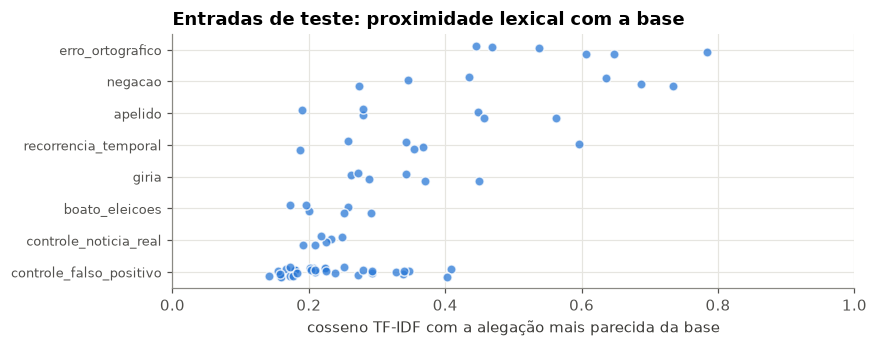

,casos,cos_mediano
tipo,,
alarmista_extremo,1,0.24
apelido,6,0.36
boato_alarmista,1,0.23
boato_conspiratorio,1,0.26
boato_eleicoes,6,0.23
controle_falso_positivo,32,0.21
controle_noticia_real,6,0.22
erro_ortografico,6,0.57
giria,6,0.32


In [22]:
tf_c = TfidfVectorizer(sublinear_tf=True, strip_accents="unicode", ngram_range=(1, 2), min_df=1)
Xc = tf_c.fit_transform(chec.alegacao)
S = cosine_similarity(tf_c.transform(entradas.texto), Xc)
entradas["cos_lexical_max"] = S.max(axis=1)
entradas["ano_mais_parecida"] = chec.ano.values[S.argmax(axis=1)]

fig, ax = plt.subplots(figsize=(8, 3))
# só os tipos com 6 ou mais casos; os demais têm 1 caso cada
tipos = entradas.tipo.value_counts()
ordem = entradas[entradas.tipo.isin(tipos[tipos >= 6].index)].groupby("tipo").cos_lexical_max.median().sort_values().index
for i, t in enumerate(ordem):
    v = entradas[entradas.tipo == t].cos_lexical_max
    ax.scatter(v, np.full(len(v), i) + np.random.default_rng(0).uniform(-.15, .15, len(v)),
               s=36, color=CORES[0], alpha=.75, edgecolor="white", linewidth=1)
ax.set_yticks(range(len(ordem)), ordem, fontsize=8.5)
ax.set_xlabel("cosseno TF-IDF com a alegação mais parecida da base")
ax.set_xlim(0, 1)
ax.set_title("Entradas de teste: proximidade lexical com a base")
salvar(fig, "entradas_proximidade")

entradas.groupby("tipo").agg(casos=("texto", "size"), cos_mediano=("cos_lexical_max", "median")).round(2)

- As entradas de teste são **tão curtas quanto as alegações** (mediana de 12 e 15 palavras), mas as
  mensagens reais de WhatsApp da seção 2 têm mediana de 30 a 57 palavras. O benchmark testa a busca
  com frases parecidas com títulos; mensagens encaminhadas reais, longas e com várias alegações, não
  estão representadas. Vale incluir no benchmark casos com o tamanho do WhatsApp.
- Na proximidade **lexical**, as reescritas com erro de ortografia e com negação continuam perto da
  alegação original (cosseno mediano 0,53-0,57); as com **gíria e apelido** caem para 0,32-0,36, quase
  o nível dos controles que não deveriam casar (0,21-0,22). Só palavras não bastam para esses casos: é
  o motivo da normalização da consulta e dos embeddings (`05_avaliacao.ipynb`). Esta medida é um
  limite inferior, já que a busca real usa embeddings.

## 4. Conclusões e implicações

**Base de checagens (camada 1)**

| Achado | Implicação |
|---|---|
| 94% `falso`; variedade de veredito só no Google Fact Check e FACTCK.BR | resposta "já checado" quase sempre mostra "falso"; não usar a base para treinar classificador |
| Nada entre dez/2022 e set/2025 | boatos desse período só são achados se reciclarem narrativas antigas; priorizar atualização pelo Google Fact Check (`scripts/atualizar_checagens_factcheck.py`) |
| Boatos.org = 46% da base | os resultados da busca tendem a mostrar o Boatos.org; considerar diversidade de agências no top-k |
| 2022: 1 em 6 alegações sobre urna/TSE, 1 em 3 sobre Lula/PT | a base cobre bem o tipo de boato mais provável em 2026 |
| 35-43% das alegações de FACTCK.BR e FactPolCheckBr são desmentidos com "não" | causa previsível de "notícia parecida" pela regra de negação; medir na calibração quantos casos vêm daí |
| Benchmark com frases curtas (12-15 palavras) x WhatsApp real com 30-57 | incluir no benchmark mensagens longas, com várias alegações |
| Gíria e apelido derrubam a proximidade lexical ao nível dos controles | justifica normalização da consulta e embeddings em vez de busca só por palavras |

**Base de treino (camada 2)**

| Achado | Implicação |
|---|---|
| Fake.br: o ano sozinho separa as classes (AUC 0,76); termos de agência de notícias = verdadeiro | o modelo aprende a época e o veículo; ajuda a explicar o no-go da camada 2 |
| WhatsApp verdadeiro = convites de grupo e propaganda de candidatos do Tocantins | o rótulo carrega a geografia da coleta, que não se repete em 2026 |
| WhatsApp: falsas têm o dobro do tamanho (AUC 0,63-0,67 só com o tamanho) | comparar o classificador com um baseline só de tamanho antes de qualquer nova tentativa |
| "verdadeiro" significa coisas diferentes em cada fonte | treinar só com WhatsApp ou tratar como "desinformativo x não desinformativo" |
| Treino é 72% Fake.br, teste é 100% WhatsApp; formato (emoji, negrito, link) só existe no WhatsApp | descompasso de domínio entre treino e uso real |
| 9% do teste tem uma variação da mesma corrente no treino | métrica otimista para 2026, como já registrado |
| "repassar", "urgente", "!!" mais comuns nas falsas do WhatsApp | bons candidatos a sinais explicáveis (RF-08), independentes de modelo |